In [1]:
no_of_threads = "12"

import os
os.environ["VECLIB_MAXIMUM_THREADS"] = no_of_threads
os.environ["OMP_NUM_THREADS"] = no_of_threads


In [2]:
%pip install matplotlib


Note: you may need to restart the kernel to use updated packages.


In [3]:
B=8 #Batchsize

In [4]:


import torch
from torch import linalg as LA
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
import time
import statistics
from typing import Tuple
from typing_extensions import Annotated
import transformers
import psutil

from transformers import AutoModelForCausalLM, AutoTokenizer
import json
import platform
import subprocess
import time
import re

In [5]:
import platform, re, subprocess, sys

def sysctl(name):
    return subprocess.run(["sysctl", "-n", name], capture_output=True, text=True).stdout.strip()

print("chip:", sysctl("machdep.cpu.brand_string"))
print("performance cores:", sysctl("hw.perflevel0.physicalcpu"))
print("efficiency cores:", sysctl("hw.perflevel1.physicalcpu"))
print("memory (GB):", int(sysctl("hw.memsize")) / 2**30)
print("macOS:", platform.mac_ver()[0], platform.machine())
print("python:", sys.executable)
print("torch:", torch.__version__, re.findall(r"BLAS_INFO=\w+", torch.__config__.show()))

chip: Apple M3 Pro
performance cores: 6
efficiency cores: 6
memory (GB): 36.0
macOS: 26.6.2 arm64
python: /opt/homebrew/Caskroom/miniforge/base/envs/torch_openblas/bin/python
torch: 2.14.1 ['BLAS_INFO=open']


In [6]:
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
REVISION = "989aa7980e4cf806f80c7fef2b1adb7bc71aa306"   

#model_hf = AutoModelForCausalLM.from_pretrained(
#    MODEL_ID, revision=REVISION, dtype=torch.float32, device_map="cpu"
#)

model_hf = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, revision=REVISION, dtype=torch.float32
)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION)

W1106 22:27:45.178000 86490 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

In [7]:


def extract_letter(text):
   
    for pat in (r"answer is\s*:?\s*\(?([A-E1-5])\b",  
                r"^\s*\(?([A-E1-5])[\).:]",           
                r"\b([A-E1-5])[\).]"):                
        m = re.search(pat, text, re.I | re.M)
        if m:
            return m.group(1).upper()
    return None

tokenizer.padding_side = "left"
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

def time_counter(no_of_threads: int, model, tokenizer, prompts: list, results: list,
                 answer_keys: list = None, max_new_tokens: int = 128,
                 batch_size: int = B, repeats: int = 3):

    torch.set_num_threads(int(no_of_threads))
    print("threads:", torch.get_num_threads())
    time.sleep(2)
    proc = psutil.Process(os.getpid())

    for start in range(0, len(prompts), batch_size):
        ids = list(range(start, min(start + batch_size, len(prompts))))
        texts = [tokenizer.apply_chat_template([{"role": "user", "content": prompts[i]}],
                                               tokenize=False, add_generation_prompt=True)
                 for i in ids]
        
        
        model_inputs = tokenizer(texts, return_tensors="pt", padding=True).to(model.device)
        print(model_inputs["input_ids"][:, :5])
        print(tokenizer.pad_token_id)
        input_len = model_inputs["input_ids"].shape[1]

        with torch.inference_mode():
            
            model.generate(**model_inputs, max_new_tokens=max_new_tokens, do_sample=False,
                               pad_token_id=tokenizer.pad_token_id)

            n_lst = []
            for i in range(repeats):
                start_time = time.perf_counter()
                out_put_ids = model.generate(**model_inputs, max_new_tokens=max_new_tokens, do_sample=False,
                               pad_token_id=tokenizer.pad_token_id)
                end_time = time.perf_counter()
                n_lst.append(end_time - start_time)

        mean = statistics.mean(n_lst)
        stndev = statistics.stdev(n_lst) if len(n_lst) > 1 else 0.0
        mem_gb = proc.memory_info().rss / 1e9
        gen = out_put_ids[:, input_len:]
        n_new = (gen != tokenizer.pad_token_id).sum(dim=1).tolist()
        for row, pid in enumerate(ids):
            answer = tokenizer.decode(gen[row], skip_special_tokens=True)
            letter = extract_letter(answer)
            n_dict = {
                'thread': torch.get_num_threads(),
                'batch_size': batch_size,
                'batch_start': start,
                'prompt_id': pid,
                'batch_mean': mean,
                'batch_stdev': stndev,
                'input_tokens': input_len,
                'new_tokens': n_new[row],
                'mem_gb': mem_gb,
                'answer': answer,
                'pred': letter,
            }
            if answer_keys is not None:
                n_dict['key'] = answer_keys[pid]
                n_dict['correct'] = (letter == answer_keys[pid])
            results.append(n_dict)


        

In [8]:
results = []

# 64 questions, 16 each of A/B/C/D. Built by select_prompts.py
with open("prompts_arc64_balanced.json") as f:
    data = json.load(f)
prompts, answer_keys = data["prompts"], data["answer_keys"]
print(len(prompts), len(answer_keys))   # 64 64

64 64


In [9]:


run_name = datetime.now().strftime(f"openblas_64p_batch{B}_%Y-%m-%d_%H-%M")  
os.makedirs("results", exist_ok=True)
csv_file = f"results/{run_name}.csv"
print("saving to", csv_file)

results = []

for t in range(1,13):
    time_counter(t, model_hf, tokenizer, prompts, results, answer_keys=answer_keys)
    pd.DataFrame(results).to_csv(csv_file, index=False)
    print("saved after", t, "threads,", len(results), "rows")
    

saving to results/openblas_64p_batch8_2026-11-06_22-27.csv
threads: 1
tensor([[151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151644,   8948,    198,   2610,    525],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643]])
151643
tensor([[151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151644,   8948,    198,   2610,    525]])
151643
tensor([[151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [15164

In [10]:
results

[{'thread': 1,
  'batch_size': 8,
  'batch_start': 0,
  'prompt_id': 0,
  'batch_mean': 91.72305380533605,
  'batch_stdev': 1.9595702244156976,
  'input_tokens': 145,
  'new_tokens': 88,
  'mem_gb': 7.736737792,
  'answer': 'B. Protein is made up of amino acids.\n\nExplanation: Proteins are composed of long chains of amino acids linked together through peptide bonds. Each amino acid has a specific sequence that determines its function within the protein structure. The process of forming proteins from amino acids is called protein synthesis or translation in molecular biology. This involves the ribosome reading the genetic code encoded in mRNA to assemble the correct sequence of amino acids into a functional protein.',
  'pred': 'B',
  'key': 'B',
  'correct': True},
 {'thread': 1,
  'batch_size': 8,
  'batch_start': 0,
  'prompt_id': 1,
  'batch_mean': 91.72305380533605,
  'batch_stdev': 1.9595702244156976,
  'input_tokens': 145,
  'new_tokens': 128,
  'mem_gb': 7.736737792,
  'answer'

In [11]:
print(torch.__config__.show())

PyTorch built with:
  - GCC 4.2
  - C++ Version: 202002
  - clang 21.1.8
  - OpenMP 202011
  - LAPACK is enabled (usually provided by MKL)
  - NNPACK is enabled
  - CPU capability usage: DEFAULT
  - Build settings: BLAS_INFO=open, BUILD_TYPE=Release, COMMIT_SHA=Unknown, CUDA_FLAGS= -DLIBCUDACXX_ENABLE_SIMPLIFIED_COMPLEX_OPERATIONS -Xfatbin -compress-all  -Wno-deprecated-gpu-targets --expt-extended-lambda -DCUB_WRAPPED_NAMESPACE=at_cuda_detail -DDISABLE_CUSPARSE_DEPRECATED -DCUDA_HAS_FP16=1 -D__CUDA_NO_HALF_OPERATORS__ -D__CUDA_NO_HALF_CONVERSIONS__ -D__CUDA_NO_HALF2_OPERATORS__ -D__CUDA_NO_BFLOAT16_CONVERSIONS__ -DC10_NODEPRECATED, CXX_COMPILER=/Users/runner/miniforge3/conda-bld/libtorch_1791585336308/_build_env/bin/arm64-apple-darwin20.0.0-clang++, CXX_FLAGS=-ftree-vectorize -fPIC -fstack-protector-strong -O2 -pipe -stdlib=libc++  -fmessage-length=0 -isystem /Users/runner/miniforge3/conda-bld/libtorch_1791585336308/_h_env_placehold_placehold_placehold_placehold_placehold_placehold_pla

In [12]:
df = pd.DataFrame(results)
per_batch = df.drop_duplicates(["thread", "batch_start"])        
total = per_batch.groupby("thread")["batch_mean"].sum()          
t1 = total.loc[1]

n_res = []
for n, t in total.items():
    speedup = t1 / t
    n_res.append({
        "threads": n,
        "mean": t,
        "speedup": speedup,
        "efficiency": speedup / n * 100,
        "serial_fraction": ((n / speedup - 1) / (n - 1)) * 100 if n > 1 else None,
    })

In [13]:
n_res

[{'threads': 1,
  'mean': 748.9980546247292,
  'speedup': np.float64(1.0),
  'efficiency': np.float64(100.0),
  'serial_fraction': None},
 {'threads': 2,
  'mean': 542.7851318327399,
  'speedup': np.float64(1.3799163070213465),
  'efficiency': np.float64(68.99581535106732),
  'serial_fraction': np.float64(44.936326197720724)},
 {'threads': 3,
  'mean': 539.1908421519911,
  'speedup': np.float64(1.3891149405196985),
  'efficiency': np.float64(46.303831350656615),
  'serial_fraction': np.float64(57.98242508563165)},
 {'threads': 4,
  'mean': 543.8821321669191,
  'speedup': np.float64(1.3771330410149591),
  'efficiency': np.float64(34.42832602537398),
  'serial_fraction': np.float64(63.48616729753199)},
 {'threads': 5,
  'mean': 545.8090390140036,
  'speedup': np.float64(1.3722712543892344),
  'efficiency': np.float64(27.445425087784685),
  'serial_fraction': np.float64(66.08986259107684)},
 {'threads': 6,
  'mean': 549.7202461386721,
  'speedup': np.float64(1.3625076752872358),
  'effici

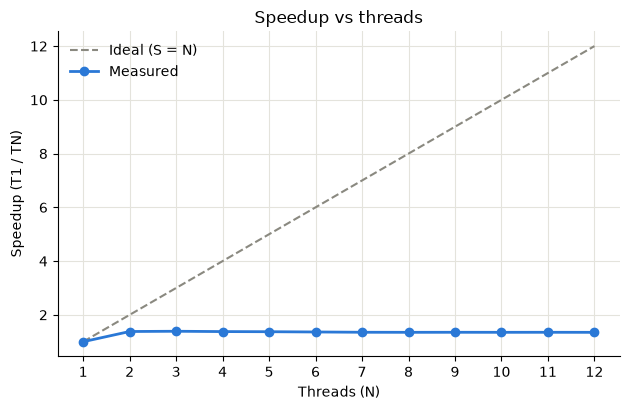

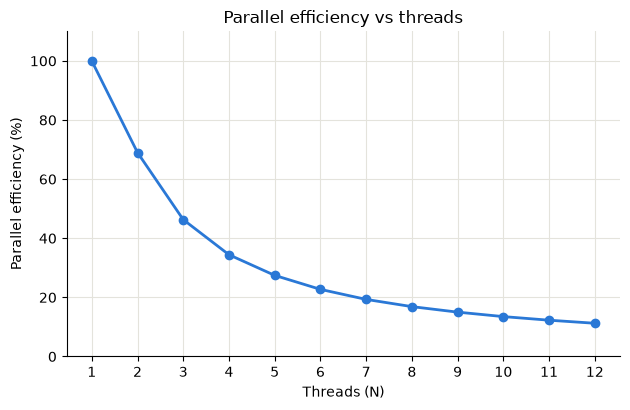

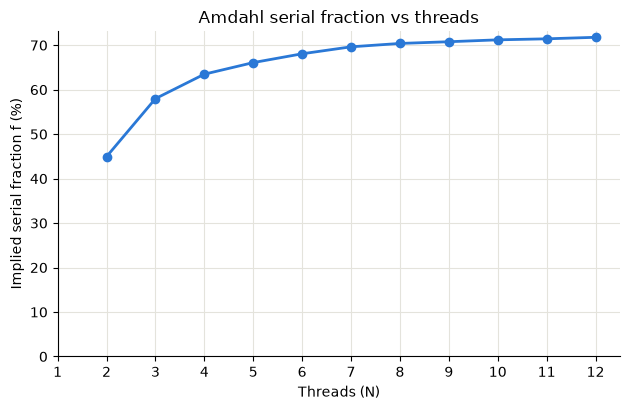

In [14]:


threads = [r["threads"] for r in n_res]
speedup = [r["speedup"] for r in n_res]
efficiency = [r["efficiency"] for r in n_res]

f_threads = [n for n in threads if n > 1]
serial = [((n / s) - 1) / (n - 1) * 100 for n, s in zip(threads, speedup) if n > 1]

BLUE, GREY = "#2a78d6", "#8a8980"

def tidy(ax, ylabel, title):
    ax.set_xlabel("Threads (N)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xticks(threads)
    ax.grid(True, color="#e4e3dc")
    ax.spines[["top", "right"]].set_visible(False)

# 1. Speedup vs ideal
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(threads, threads, "--", color=GREY, label="Ideal (S = N)")
ax.plot(threads, speedup, "o-", color=BLUE, linewidth=2, label="Measured")
tidy(ax, "Speedup (T1 / TN)", "Speedup vs threads")
ax.legend(frameon=False)
fig.tight_layout(); plt.show()

# 2. Efficiency
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(threads, efficiency, "o-", color=BLUE, linewidth=2)
ax.set_ylim(0, 110)
tidy(ax, "Parallel efficiency (%)", "Parallel efficiency vs threads")
fig.tight_layout(); plt.show()

# 3. Serial fraction
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(f_threads, serial, "o-", color=BLUE, linewidth=2)
ax.set_ylim(bottom=0)
tidy(ax, "Implied serial fraction f (%)", "Amdahl serial fraction vs threads")
fig.tight_layout(); plt.show()